# Forecasting Short-Term Stock Market Volatility

**Research question:** Can machine learning predict the volatility of a stock over its next five trading days using historical price movements, trading volume, and market trends?

## Motivation and Practical Application

Financial market can experience many changes even in a single day. Some period of relative stability and others of substantial price fluctuations. That's why it is important to understand what will happen to the market. 

An important characteristic of market timeline is **volatility clustering:** large price movement tend to happen with other large movements, while calmer periods tend to persist.

This application can assist investors and risk analysts by estimating stock's expected daily volatility over the next five trading days. For example, an analyst could compare the predicted volatility of different stock's and identify which one may require additional risk monitoring. 

## Introduction

I plan to build a regression model that analyzes stock price history and predicts the magnitude of future price fluctuations. 

I will focus on three things:

- **Prediction:** Estimate future volatility using data available at a fixed point in time.

- **Comparison:** Compare such ML algorithm with simple historical models.

  **Note:** Such comparison is not trivial, see [Forecasting realized volatility: Does anything beat linear models?](https://www.sciencedirect.com/science/article/abs/pii/S0927539824000598?via%3Dihub)

- **Evaluation:** Measure how accurately models predict volatility on unseen data.

## Target Interpretation

In the future section we will do feature engineering to process data. With that data we will estimate at the end of trading day $t$ how large the stock's daily price changes will be, on average, measured as the root mean square (RMS) of daily log returns, during trading days $t+1$ to $t+5$.

Define the closing price on trading day $t$ as $C(t)$.

### Daily Logarithm Return

$$
r(t) = \ln\left(\frac{\text{C}(t)}{\text{C}(t-1)}\right)
$$

I am using logarithmic return because 

- Log returns add over time, so $r(t) + r(t + 1)$ is the log return over two days.
- For typical daily price changes they are close to simple percentage returns ($\ln(x + 1) \approx x$)

### Five Session Realized Volatility

$$
y(t) = \sqrt{ \frac{r(t+1)^2 + r(t+2)^2 + r(t+3)^2 + r(t+4)^2 + r(t+5)^2}{5} }
$$

### Worked Example *(Illustrative, Not Market Data)*

Suppose a stock records the following daily log returns ($r_t$) over the next 5 trading sessions:

| Future Session ($t$) | 1 | 2 | 3 | 4 | 5 |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Daily Log Return ($r_t$)** | $+2\%$ | $-1\%$ | $+3\%$ | $-2\%$ | $+1\%$ |
| **Squared Return ($r_t^2$)** | $4$ | $1$ | $9$ | $4$ | $1$ |

We compute the target **$y$** (5-day Root Mean Square daily volatility) as:

$$
\begin{aligned}
y &= \sqrt{\frac{1}{5} \sum_{t=1}^{5} r_t^2} = \sqrt{\frac{2^2 + (-1)^2 + 3^2 + (-2)^2 + 1^2}{5}} \\
  &= \sqrt{\frac{19}{5}} = \sqrt{3.8} \approx \mathbf{1.95\%} \text{ daily RMS volatility}
\end{aligned}
$$

## Success Criterion

The selected ML model has **lower held-out test RMSE** than the past 20-session RMS-volatility baseline.

### Import

In [1]:
# Imports and global settings. Everything the notebook needs lives here.
from pathlib import Path
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

# House plotting theme.
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["savefig.dpi"] = 200          # sharp figures for the PDF report
plt.rcParams["savefig.bbox"] = "tight"

# Paths.
DATA_DIR = Path("us-daily-data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Universe: 20 large caps across sectors, plus SPY as the market proxy.
TICKERS = [
    "AAPL", "MSFT", "NVDA", "AMD", "INTC",   # technology
    "JPM", "BAC", "V", "MA",                 # finance
    "WMT", "COST", "KO", "PG",               # consumer
    "JNJ", "PFE",                            # healthcare
    "XOM", "CVX", "CAT",                     # energy / industrial
    "DIS", "NFLX",                           # media
]
MARKET = "SPY"

# Experiment design.
HORIZON = 5                  # predict volatility over the next 5 trading days
START = "2018-01-01"         # first modelling date (load from 2017 for feature warm-up)
TRAIN_END = "2023-12-31"     # train: 2018-2023
VAL_END = "2024-12-31"       # validation: 2024, test: 2025 onward

# Reproducibility.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Imports ready. Seed fixed at", RANDOM_STATE)

Imports ready. Seed fixed at 42


## Data Collection

The model uses historical data from Stooq for 20 large-cap US stocks across many industries, such as technology, financials, healthcare, etc. (for more details look below), together with SPY for more market conditions (look for definition below).

**Dataset:** [Stooq Historical Data](https://stooq.com/db/h/?).

**Download data for usage:** U.S. → Daily → ASCII

Extract zip into the folder with this file. Expected workspace:

| Path | Type | Description |
| :--- | :--- | :--- |
| `root/` | Directory | Main project workspace |
| ├── `stock-market-volatility-predictor.ipynb` | Notebook | Core code, analysis, and volatility prediction model |
| └── `data/` | Directory | Raw historical market data files |

#### Expected bulk ASCII columns

```python3
<TICKER>,<PER>,<DATE>,<TIME>,<OPEN>,<HIGH>,<LOW>,<CLOSE>,<VOL>,<OPENINT>
AAPL.US,D,20261113,000000,357.96,360.83,355.75,356.27,40027467,0
```

Run python code below to format downloaded file into us-daily-data folder.

In [4]:
# One-time data setup: flatten the extracted Stooq download (data/daily/us) into us-daily-data/.
import shutil
from pathlib import Path

src = Path("data") / "daily" / "us"      # what the Stooq zip creates when extracted here
dst = Path("us-daily-data")              # what the rest of the notebook reads
REQUIRED = ["nasdaq stocks", "nyse stocks", "nyse etfs"]

if not dst.exists():
    assert Path("data").is_dir(), (
        "Expected a 'data' folder next to this notebook. "
        "Download U.S. -> Daily -> ASCII from Stooq and extract the zip into this folder."
    )
    assert src.is_dir(), (
        f"Found 'data' but not '{src}'. Make sure you downloaded the U.S. Daily ASCII archive."
    )
    shutil.move(str(src), str(dst))
    # remove the now-empty data/daily and data folders (left alone if anything else is in them)
    for leftover in (Path("data") / "daily", Path("data")):
        if leftover.is_dir() and not any(leftover.iterdir()):
            leftover.rmdir()
    print(f"Moved {src} -> {dst}")
else:
    print(f"{dst} already exists, skipping the move.")

missing = [g for g in REQUIRED if not (dst / g).is_dir()]
assert not missing, f"{dst} is missing expected folders: {missing}"
assert any(dst.rglob("aapl.us.txt")), f"{dst} has no aapl.us.txt; the download looks incomplete."
print(f"Data ready: {sum(1 for _ in dst.rglob('*.txt')):,} files in {dst}")

us-daily-data already exists, skipping the move.
Data ready: 13,345 files in us-daily-data


### Dataset Structure (`us-daily-data/` — 13,345 Total Files)

| Directory / Subfolder | File Count | Alphabetical Range | Key Tickers Included |
| :--- | :---: | :--- | :--- |
| **`nasdaq stocks/`** | **4,642** | *3 subfolders* | |
| ↳ `1/` | 2,000 | `aaap` … `hviiu` | `AAPL`, `AMD`, `COST` |
| ↳ `2/` | 2,000 | `hvmc` … `sy` | `MSFT`, `NVDA`, `INTC`, `NFLX` |
| ↳ `3/` | 642 | `sybt` … `zyn` | `WMT` |
| **`nasdaq etfs/`** | **987** | `aadr` … `ztwo` *(no subfolders)* | `QQQ` |
| **`nyse stocks/`** | **4,488** | *3 subfolders* | |
| ↳ `1/` | 2,000 | `a` … `idvz` | `BAC`, `CAT`, `CVX`, `DIS` |
| ↳ `2/` | 2,000 | `idyn` … `tsm` | `JPM`, `MA`, `KO`, `PG`, `JNJ`, `PFE` |
| ↳ `3/` | 488 | `t_a` … `zws` | `V`, `XOM` |
| **`nyse etfs/`** | **2,905** | *2 subfolders* | |
| ↳ `1/` | 2,000 | `aaa` … `ptlc` | — |
| ↳ `2/` | 905 | `ptmc` … `ztax` | `SPY` |
| **`nysemkt stocks/`** | **321** | `accs` … `zone` *(no subfolders)* | — |
| **`nysemkt etfs/`** | **2** | `iqei`, `iqel` *(no subfolders)* | — |

* **`nasdaq stocks`** — Individual companies listed on Nasdaq. Tech-heavy: `AAPL`, `MSFT`, `NVDA`, `AMD`, `INTC`, `COST`, `NFLX`.
* **`nasdaq etfs`** — Funds listed on Nasdaq (`QQQ`, the Nasdaq-100 fund).
* **`nyse stocks`** — Individual companies listed on the New York Stock Exchange. Older blue chips: `JPM`, `KO`, `XOM`, `JNJ`.
* **`nyse etfs`** — Funds listed on NYSE (in practice its Arca platform, where most US ETFs trade).
* **`nysemkt stocks`** — Companies on NYSE American, formerly the American Stock Exchange (AMEX). Mostly small-cap companies.
* **`nysemkt etfs`** — The few funds listed on NYSE American.

##### Quick Term Guide

* **Stock vs. ETF** — A **stock** is a share of ownership in one company. An **ETF** (Exchange-Traded Fund) holds a basket of securities and trades like a single stock; `SPY` holds the S&P 500, so its price tracks the broader US market.
* **`SPY` (SPDR S&P 500 ETF Trust)** — An exchange-traded fund tracking the S&P 500 (`us-daily-data/nyse etfs/2/spy.us.txt`), used as a proxy feature to capture broad, market-wide volatility that individual stock histories miss.
* **Nasdaq vs. NYSE** — The two largest US stock exchanges. **Nasdaq** is an all-electronic exchange known for growth and tech companies; **NYSE** is the traditional floor-and-electronic exchange known for established corporations.
* **Blue Chips** — Large, well-established, financially sound companies with a long history of reliable performance (e.g., `JPM`, `KO`, `JNJ`).
* **S&P 500 / Nasdaq-100** — Market indexes. The **S&P 500** tracks 500 leading US companies across all sectors; the **Nasdaq-100** tracks the 100 largest non-financial companies on Nasdaq.
* **Small-Cap** — Companies with a smaller total market value (typically $300M–$2B), often carrying higher growth potential and higher volatility.
* **Numbered Subfolders (`1`, `2`, `3`)** — Arbitrary chunks with no market meaning. **Stooq** (the historical market data provider) splits large folders alphabetically into batches of ~2,000 files (`nasdaq stocks/1` starts at `aaap` and holds 2,000 files).
* **Unified Schema** — The CSV file format is identical across all six folders, so the exact same loading code works everywhere.

## Data Cleaning

As seen from above downloaded data set is vast, so we will first make some data cleaning. We will keep the following stocks:

| Sector | Tickers | Count |
| :--- | :--- | :---: |
| **Technology** | `AAPL`, `MSFT`, `NVDA`, `AMD`, `INTC` | 5 |
| **Financials** | `JPM`, `BAC`, `V`, `MA` | 4 |
| **Consumer** | `WMT`, `COST`, `KO`, `PG` | 4 |
| **Healthcare** | `JNJ`, `PFE` | 2 |
| **Energy / Industry** | `XOM`, `CVX`, `CAT` | 3 |
| **Media / Entertainment** | `DIS`, `NFLX` | 2 |

We can safely use pandas ```read_csv``` even though files are ```.txt```, because they are comma separated. Code below **permanently** deletes 13,324 files, making data weight not too much!

In [9]:
# One-time data clean: keep only the needed ticker files in us-daily-data/ and delete the rest.
DATA_DIR = Path("us-daily-data")
REQUIRED = ["nasdaq stocks", "nyse stocks", "nyse etfs"]
tmp = Path("us-daily-data-small")
wanted = TICKERS + [MARKET]

assert DATA_DIR.is_dir(), f"{DATA_DIR} does not exist. Run the setup cell above first."
n_before = sum(1 for _ in DATA_DIR.rglob("*.txt"))

if n_before == len(wanted):
    print(f"{DATA_DIR} already holds only the {n_before} needed files, nothing to do.")
else:
    # 1. Locate every needed file before touching anything.
    found = {}
    for symbol in wanted:
        name = f"{symbol.lower()}.us.txt"
        matches = [p for g in REQUIRED for p in (DATA_DIR / g).rglob(name)]
        assert len(matches) == 1, f"{symbol}: expected exactly one file named {name}, found {len(matches)}"
        found[symbol] = matches[0]

    # 2. Copy them to a temporary folder, keeping the same sub-folder layout.
    if tmp.exists():
        shutil.rmtree(tmp)
    for path in found.values():
        target = tmp / path.relative_to(DATA_DIR)
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, target)

    # 3. Verify the copies are complete before deleting the originals.
    for path in found.values():
        copy = tmp / path.relative_to(DATA_DIR)
        assert copy.is_file() and copy.stat().st_size == path.stat().st_size, f"Copy failed for {path}"

    # 4. Only now replace the big folder with the small one.
    shutil.rmtree(DATA_DIR)
    tmp.rename(DATA_DIR)
    n_after = sum(1 for _ in DATA_DIR.rglob("*.txt"))
    print(f"{DATA_DIR}: kept {n_after} files, removed {n_before - n_after:,}")

us-daily-data: kept 21 files, removed 13,324


### Data We Are Working With

First, we will load the data into variables to work with. 

In [10]:
# Read the needed tickers from us-daily-data/ into one table (read-only).
COLS = ["ticker", "per", "date", "time", "open", "high", "low", "close", "volume", "openint"]
LOAD_FROM = "2017-01-01"   # one year of warm-up before the 2018 modelling start

# One check covers every step above: each needed file must be findable.
files = {p.name.split(".")[0].upper(): p for p in DATA_DIR.rglob("*.us.txt")}
missing = [t for t in TICKERS + [MARKET] if t not in files]
assert not missing, f"Missing data for {missing}. Run the data setup cells above first."


def read_ticker(symbol):
    df = pd.read_csv(files[symbol], header=0, names=COLS)
    df["date"] = pd.to_datetime(df["date"].astype(str), format="%Y%m%d")
    df["ticker"] = symbol
    return df.loc[df["date"] >= LOAD_FROM, ["ticker", "date", "open", "high", "low", "close", "volume"]]


prices = pd.concat([read_ticker(t) for t in TICKERS + [MARKET]], ignore_index=True)
prices = prices.sort_values(["ticker", "date"]).reset_index(drop=True)

print(f"Loaded {len(prices):,} rows for {prices['ticker'].nunique()} tickers, "
      f"{prices['date'].min().date()} to {prices['date'].max().date()}")
display(prices.groupby("ticker")["date"].agg(["min", "max", "count"]))

Loaded 52,101 rows for 21 tickers, 2017-01-03 to 2026-11-13


,min,max,count
ticker,,,
AAPL,2017-01-03,2026-11-13,2481
AMD,2017-01-03,2026-11-13,2481
BAC,2017-01-03,2026-11-13,2481
CAT,2017-01-03,2026-11-13,2481
COST,2017-01-03,2026-11-13,2481
CVX,2017-01-03,2026-11-13,2481
DIS,2017-01-03,2026-11-13,2481
INTC,2017-01-03,2026-11-13,2481
JNJ,2017-01-03,2026-11-13,2481


Let's take a look at how data looks.

Example input rows (most recent five trading days of AAPL):


,ticker,date,open,high,low,close,volume
2476,AAPL,2026-11-09,344.733,352.0630,344.518,350.424,4.879009e+07
2477,AAPL,2026-11-10,351.083,353.6010,346.197,348.245,2.977867e+07
2478,AAPL,2026-11-11,349.280,355.6400,349.060,355.360,3.447965e+07
2479,AAPL,2026-11-12,357.810,359.3684,354.410,354.880,3.187498e+07
2480,AAPL,2026-11-13,357.960,360.8300,355.750,356.270,4.002747e+07


Summary per ticker:


,first_day,last_day,days,min_close,max_close,avg_volume_millions
ticker,,,,,,
AAPL,2017-01-03,2026-11-13,2481,26.65,356.27,95.1
AMD,2017-01-03,2026-11-13,2481,9.53,649.42,61.9
BAC,2017-01-03,2026-11-13,2481,15.46,64.48,60.5
CAT,2017-01-03,2026-11-13,2481,74.47,1060.40,4.0
COST,2017-01-03,2026-11-13,2481,133.18,1106.21,2.5
CVX,2017-01-03,2026-11-13,2481,40.83,235.52,10.6
DIS,2017-01-03,2026-11-13,2481,76.91,195.76,11.0
INTC,2017-01-03,2026-11-13,2481,18.13,140.94,51.1
JNJ,2017-01-03,2026-11-13,2481,85.74,285.75,8.9


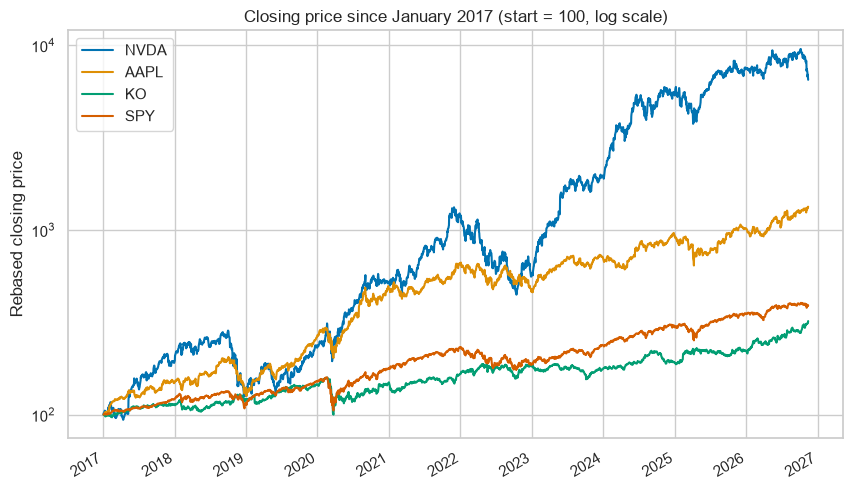

In [13]:
# A first look at the data: example rows, summary statistics, and price history.
print("Example input rows (most recent five trading days of AAPL):")
display(prices[prices["ticker"] == "AAPL"].tail(5))

print("Summary per ticker:")
overview = prices.groupby("ticker").agg(
    first_day=("date", "min"), last_day=("date", "max"), days=("date", "size"),
    min_close=("close", "min"), max_close=("close", "max"), avg_volume_millions=("volume", "mean"),
)
overview["avg_volume_millions"] /= 1e6
display(overview.round({"min_close": 2, "max_close": 2, "avg_volume_millions": 1}))

# Price history for a few contrasting stocks, rebased so they start at 100 and can share one axis.
SHOW = ["NVDA", "AAPL", "KO", "SPY"]
wide = prices[prices["ticker"].isin(SHOW)].pivot(index="date", columns="ticker", values="close")[SHOW]
rebased = 100 * wide / wide.iloc[0]

ax = rebased.plot(logy=True, linewidth=1.5)
ax.set_title("Closing price since January 2017 (start = 100, log scale)")
ax.set_xlabel("")
ax.set_ylabel("Rebased closing price")
ax.legend(title="")
plt.savefig(FIG_DIR / "price_history.png")
plt.show()

## Feature Engineering

We will design features for a better data interpretation. The model might benefit from knowing:
- How much has the stock changed recently?
- Has the stock become more volatile than usual?
- Are daily trading ranges increasing?
- What happens to trading activity?

| Feature | Mathematical Definition | Motivation |
| :--- | :--- | :--- |
| **`ret_1`** | $r(t) = \ln\left(\frac{C(t)}{C(t-1)}\right)$ | Most recent signed shock |
| **`abs_ret_1`** | $\lvert r(t) \rvert$ | Most recent shock size |
| **`return_5`** | $\ln\left(\frac{C(t)}{C(t-5)}\right)$ | Recent momentum / short-term trend |
| **`return_20`** | $\ln\left(\frac{C(t)}{C(t-20)}\right)$ | Medium-term momentum / trend |
| **`rv_5`** | $\sqrt{\frac{1}{5}\sum_{i=0}^{4} r(t-i)^2}$ | Short-term volatility persistence (5-day) |
| **`rv_10`** | $\sqrt{\frac{1}{10}\sum_{i=0}^{9} r(t-i)^2}$ | Short-term volatility persistence (10-day) |
| **`rv_20`** | $\sqrt{\frac{1}{20}\sum_{i=0}^{19} r(t-i)^2}$ | Medium-term volatility (20-day) |
| **`rv_60`** | $\sqrt{\frac{1}{60}\sum_{i=0}^{59} r(t-i)^2}$ | Longer-term volatility baseline (60-day) |
| **`range_5`** | $\frac{1}{5}\sum_{i=0}^{4} \frac{H(t-i) - L(t-i)}{C(t-i)}$ | Intraday trading range (5-day) |
| **`range_20`** | $\frac{1}{20}\sum_{i=0}^{19} \frac{H(t-i) - L(t-i)}{C(t-i)}$ | Intraday trading range (20-day) |
| **`relative_volume_20`** | $\frac{V(t)}{\frac{1}{20}\sum_{i=0}^{19} V(t-i)}$ | Unusual trading activity |
| **`mkt_rv_5`** | `rv_5` computed on SPY | Short-term market-wide volatility |
| **`mkt_rv_20`** | `rv_20` computed on SPY | Medium-term market-wide volatility |

**Notation.** For a given stock on trading day $t$: $C(t)$ is the closing price, $H(t)$ the highest price of the day, $L(t)$ the lowest price of the day, and $V(t)$ the number of shares traded (volume). $r(t)$ is the daily log return (`ret_1`). Every feature uses data up to and including day $t$ only. The two market features apply the same volatility formulas to SPY, giving 13 features in total.

In [20]:
# Feature engineering: every feature at day t uses data up to and including day t only.
def rms(series, window):
    """Root mean square over a trailing window (realized volatility)."""
    return np.sqrt((series ** 2).rolling(window).mean())


def add_features(g):
    """Compute features and target for ONE ticker (rows must be in date order)."""
    g = g.sort_values("date").copy()
    c, h, l, v = g["close"], g["high"], g["low"], g["volume"]

    # Returns
    g["ret_1"] = np.log(c / c.shift(1))
    g["abs_ret_1"] = g["ret_1"].abs()
    g["return_5"] = np.log(c / c.shift(5))
    g["return_20"] = np.log(c / c.shift(20))

    # Realized volatility over trailing windows
    for w in (5, 10, 20, 60):
        g[f"rv_{w}"] = rms(g["ret_1"], w)

    # Average intraday range and relative volume
    day_range = (h - l) / c
    g["range_5"] = day_range.rolling(5).mean()
    g["range_20"] = day_range.rolling(20).mean()
    g["relative_volume_20"] = v / v.rolling(20).mean()

    # Target y(t): RMS of the NEXT five returns, r(t+1) ... r(t+5).
    # rms(...) at row t+5 covers r(t+1..t+5); shift(-HORIZON) brings that value back to row t.
    g["target"] = rms(g["ret_1"], HORIZON).shift(-HORIZON)
    g["target_end"] = g["date"].shift(-HORIZON)   # last day the target looks at (needed for the split)
    return g


featured = pd.concat([add_features(g) for _, g in prices.groupby("ticker")], ignore_index=True)

# Market-wide volatility from SPY, joined to every stock by date (not in the table above yet).
market = featured.loc[featured["ticker"] == MARKET, ["date", "rv_5", "rv_20"]]
market = market.rename(columns={"rv_5": "mkt_rv_5", "rv_20": "mkt_rv_20"})
data = featured[featured["ticker"] != MARKET].merge(market, on="date", how="left")

FEATURES = ["ret_1", "abs_ret_1", "return_5", "return_20", "rv_5", "rv_10", "rv_20", "rv_60",
            "range_5", "range_20", "relative_volume_20", "mkt_rv_5", "mkt_rv_20"]

# Keep modelling rows only: from START, with complete features (60-day warm-up) and a known target.
rows_before = len(data)
data = data[data["date"] >= START].dropna(subset=FEATURES + ["target"]).reset_index(drop=True)

print(f"{len(data):,} stock-day rows, {len(FEATURES)} features, {data['ticker'].nunique()} stocks "
      f"({rows_before - len(data):,} warm-up / no-target rows dropped)")
print(f"Dates: {data['date'].min().date()} to {data['date'].max().date()}")
print("\nExample: model inputs (features) and output (target) for AAPL")
example = data.loc[data["ticker"] == "AAPL", ["date"] + FEATURES + ["target"]].tail(3)
display(example.set_index("date").round(4))

44,500 stock-day rows, 13 features, 20 stocks (5,120 warm-up / no-target rows dropped)
Dates: 2018-01-02 to 2026-11-06

Example: model inputs (features) and output (target) for AAPL


,date,ret_1,abs_ret_1,return_5,return_20,rv_5,rv_10,rv_20,rv_60,range_5,range_20,relative_volume_20,mkt_rv_5,mkt_rv_20,target
2222,2026-11-04,0.0517,0.0517,0.0164,0.0374,0.0274,0.0205,0.0157,0.0139,0.0290,0.0202,1.9344,0.0113,0.0079,0.0161
2223,2026-11-05,-0.0154,0.0154,-0.0137,0.0110,0.0275,0.0207,0.0159,0.0139,0.0343,0.0213,1.5650,0.0230,0.0128,0.0145
2224,2026-11-06,-0.0052,0.0052,-0.0066,0.0169,0.0270,0.0208,0.0157,0.0139,0.0301,0.0212,0.9180,0.0216,0.0127,0.0144


## Leakage-Safe Experimental Design

To make sure that model never sees tests that it will be tested on, I will separate whole data into 3 parts: Train, Validation, and Test data. Each separation is done on time, so:

| Split | Forecast Dates ($t$) | Inclusion / Leakage Rule |
| :--- | :--- | :--- |
| **Training** | `2018-01-01` to `2023-12-31` | Include a row only if its 5th future trading day ($t+5$) is $\le$ `2023-12-31`. |
| **Validation** | `2024-01-01` to `2024-12-31` | Include a row only if its 5th future trading day ($t+5$) is $\le$ `2024-12-31`. |
| **Final Test** | `2025-01-01` to latest fully labeled `2026` date | Strict holdout: never used to choose features, hyperparameters, or the winning model. |

##### Why do we remove rows at the boundaries?

Because then model will use outcomes from the other split in the current one. E.g., training data will use some part of validation data, which would leak the data and show incorrect training results.

In [21]:
# Chronological split. Rows whose 5-day target window crosses a boundary are dropped (purge),
# so no training label uses returns from the validation period, and likewise for validation/test.
train = data[data["target_end"] <= TRAIN_END]
val = data[(data["date"] > TRAIN_END) & (data["target_end"] <= VAL_END)]
test = data[data["date"] > VAL_END]
train_val = data[data["target_end"] <= VAL_END]   # used to refit the final model before testing

# No row may be in two sets, and each set must end before the next one starts.
assert len(set(train.index) & set(val.index)) == 0 and len(set(val.index) & set(test.index)) == 0
assert train["target_end"].max() < val["date"].min() and val["target_end"].max() < test["date"].min()

split_summary = pd.DataFrame({
    "set": ["train", "validation", "test"],
    "first_day": [s["date"].min().date() for s in (train, val, test)],
    "last_day": [s["date"].max().date() for s in (train, val, test)],
    "rows": [len(s) for s in (train, val, test)],
    "share_%": [round(100 * len(s) / len(data), 1) for s in (train, val, test)],
    "mean_target_%": [round(100 * s["target"].mean(), 3) for s in (train, val, test)],
})
display(split_summary)
print(f"Purged rows (target window crosses a boundary): {len(data) - len(train) - len(val) - len(test)}")

,set,first_day,last_day,rows,share_%,mean_target_%
0,train,2018-01-02,2023-12-21,30080,67.6,1.693
1,validation,2024-01-02,2024-12-23,4940,11.1,1.398
2,test,2025-01-02,2026-11-06,9280,20.9,1.735


Purged rows (target window crosses a boundary): 200


# Models and Training 

First, we need helper functions to have correct model inputs and model outputs with score estimator.

In [27]:
# Models. All learned models predict log-volatility (the target is right-skewed);
# predictions are converted back with exp() before scoring.
LOG_COLS = ["abs_ret_1", "rv_5", "rv_10", "rv_20", "rv_60", "range_5", "range_20",
            "relative_volume_20", "mkt_rv_5", "mkt_rv_20"]

def make_X(df, cols=FEATURES):
    """Model inputs: log-transform the positive, skewed columns; leave signed returns as they are."""
    X = df[cols].copy()
    for col in set(cols) & set(LOG_COLS):
        X[col] = np.log(X[col].clip(lower=1e-4))
    return X


def make_y(df):
    return np.log(df["target"].clip(lower=1e-4))


def score(df, pred):
    """Errors in percentage points of daily volatility."""
    y = df["target"].values
    return {"MAE": 100 * mean_absolute_error(y, pred),
            "RMSE": 100 * np.sqrt(mean_squared_error(y, pred)),
            "R2": r2_score(y, pred)}

HAR_COLS = ["rv_5", "rv_20", "rv_60"]
val_pred, test_pred = {}, {}

# Learned models. Validation: fit on train. Test: refit on train + validation
def fit_predict(make_model, cols=FEATURES):
    v = np.exp(make_model().fit(make_X(train, cols), make_y(train)).predict(make_X(val, cols)))
    t = np.exp(make_model().fit(make_X(train_val, cols), make_y(train_val)).predict(make_X(test, cols)))
    return v, t

Now, let's consider different models to use.

| Experiment | Configuration | Reason to Include |
| :--- | :--- | :--- |
| **A. Constant median** | Median training target *(no fitting)* | Sanity check: difficulty relative to trivial guessing |
| **B. Last 5-day volatility** | `Prediction = rv_5` *(no fitting)* | Short-memory persistence |
| **C. 20-day RMS baseline** | `Prediction = rv_20` *(no fitting)* | Direct benchmark: volatility persistence |
| **D. Linear regression** | `LinearRegression` on log `rv_5`, `rv_20`, `rv_60` | Classic three-horizon volatility model |
| **E. Ridge regression** | `StandardScaler` + `Ridge(alpha=10)` on all 13 features | Interpretable regularized linear regression |
| **F. XGBoost (default)** | `XGBRegressor` with library defaults | Captures nonlinearities, untuned |
| **G. XGBoost (tuned)** | 12-configuration grid, early stopping on validation | Tests whether tuning and capacity help |


In [ ]:
# Baselines that need no training.
val_pred["Constant (train median)"] = np.full(len(val), train["target"].median())
test_pred["Constant (train median)"] = np.full(len(test), train_val["target"].median())
val_pred["Last 5-day volatility"], test_pred["Last 5-day volatility"] = val["rv_5"].values, test["rv_5"].values
BASELINE = "Baseline: 20-day volatility"
val_pred[BASELINE], test_pred[BASELINE] = val["rv_20"].values, test["rv_20"].values

val_pred["Linear regression (3 volatilities)"], test_pred["Linear regression (3 volatilities)"] = fit_predict(
    LinearRegression, HAR_COLS)
val_pred["Ridge (all features)"], test_pred["Ridge (all features)"] = fit_predict(
    lambda: make_pipeline(StandardScaler(), Ridge(alpha=10.0)))
val_pred["XGBoost (default)"], test_pred["XGBoost (default)"] = fit_predict(
    lambda: XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1))

# XGBoost tuned on the validation year: small grid, rounds chosen by early stopping.
tuning = []
for depth, rate, child in itertools.product([2, 3, 5], [0.02, 0.05], [20, 100]):
    m = XGBRegressor(n_estimators=2000, max_depth=depth, learning_rate=rate, min_child_weight=child,
                     subsample=0.8, colsample_bytree=0.8, early_stopping_rounds=100,
                     random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(make_X(train), make_y(train), eval_set=[(make_X(val), make_y(val))], verbose=False)
    s = score(val, np.exp(m.predict(make_X(val))))
    tuning.append({"max_depth": depth, "learning_rate": rate, "min_child_weight": child,
                   "rounds": m.best_iteration + 1, "val_MAE": s["MAE"], "val_RMSE": s["RMSE"]})
tuning = pd.DataFrame(tuning).sort_values("val_RMSE").reset_index(drop=True)
best = tuning.iloc[0]
BEST_PARAMS = dict(n_estimators=int(best["rounds"]), max_depth=int(best["max_depth"]),
                   learning_rate=float(best["learning_rate"]), min_child_weight=int(best["min_child_weight"]),
                   subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)
val_pred["XGBoost (tuned)"], test_pred["XGBoost (tuned)"] = fit_predict(lambda: XGBRegressor(**BEST_PARAMS))

print("XGBoost tuning, best five of", len(tuning), "configurations:")
display(tuning.head(5).round(4))

# Results table.
results = pd.DataFrame([{"model": name,
                         **{f"val_{k}": v for k, v in score(val, val_pred[name]).items()},
                         **{f"test_{k}": v for k, v in score(test, test_pred[name]).items()}}
                        for name in val_pred]).set_index("model")
for part in ("val", "test"):
    results[f"{part}_RMSE_vs_baseline_%"] = 100 * (results[f"{part}_RMSE"] / results.loc[BASELINE, f"{part}_RMSE"] - 1)
display(results.round(4))

XGBoost tuning, best five of 12 configurations:


,max_depth,learning_rate,min_child_weight,rounds,val_MAE,val_RMSE
0,2,0.05,20,601,0.4965,0.8517
1,3,0.05,20,119,0.4950,0.8521
2,5,0.05,100,65,0.4949,0.8523
3,3,0.05,100,196,0.4963,0.8525
4,5,0.02,20,163,0.4946,0.8526


,val_MAE,val_RMSE,val_R2,test_MAE,test_RMSE,test_R2,val_RMSE_vs_baseline_%,test_RMSE_vs_baseline_%
model,,,,,,,,
Constant (train median),0.6707,1.0421,-0.0019,0.7899,1.3997,-0.1013,8.2771,18.7014
Last 5-day volatility,0.7003,1.1308,-0.1797,0.8284,1.3159,0.0266,17.4965,11.5934
Baseline: 20-day volatility,0.6200,0.9624,0.1455,0.7531,1.1792,0.2184,0.0000,0.0000
Linear regression (3 volatilities),0.5213,0.8790,0.2873,0.6493,1.1124,0.3043,-8.6729,-5.6587
Ridge (all features),0.4988,0.8466,0.3389,0.6273,1.0682,0.3585,-12.0407,-9.4075
XGBoost (default),0.5309,0.8812,0.2836,0.7008,1.2102,0.1767,-8.4403,2.6323
XGBoost (tuned),0.4965,0.8517,0.3308,0.6499,1.1114,0.3056,-11.5067,-5.7440


## Evaluation and results analysis

For each model from above we will consider MAE (lower is better), RMSE (lower is better) and $\text{R}^2$ (higher is better) errors. As well as show relative improvement from the baseline.

$$
\text{Improvement}(\%) = 100 \times (1 - \text{RMSE}(\text{model}) / \text{RMSE}(\text{baseline}))
$$

,Test MAE,Test RMSE,Test R2,Improvement (%)
model,,,,
Ridge (all features),0.627,1.068,0.36,9.4
XGBoost (tuned),0.650,1.111,0.31,5.7
Linear regression (3 volatilities),0.649,1.112,0.30,5.7
Baseline: 20-day volatility,0.753,1.179,0.22,0.0
XGBoost (default),0.701,1.210,0.18,-2.6
Last 5-day volatility,0.828,1.316,0.03,-11.6
Constant (train median),0.790,1.400,-0.10,-18.7


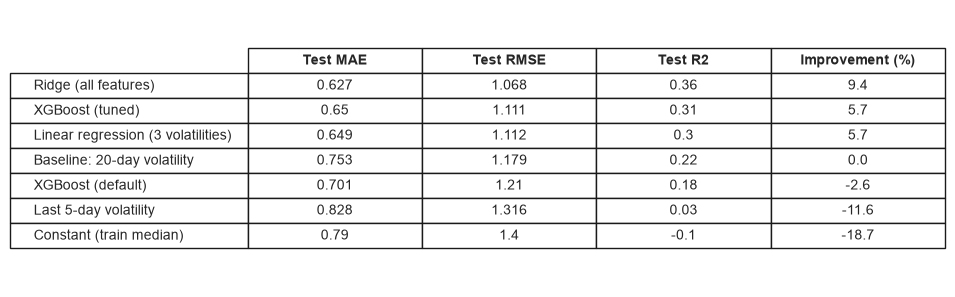

In [32]:
# Compact results table for the evaluation section (test set, sorted best to worst).
summary_table = results[["test_MAE", "test_RMSE", "test_R2"]].copy()
summary_table["Improvement (%)"] = 100 * (1 - results["test_RMSE"] / results.loc[BASELINE, "test_RMSE"])
summary_table.columns = ["Test MAE", "Test RMSE", "Test R2", "Improvement (%)"]
summary_table = summary_table.sort_values("Test RMSE")
display(summary_table.round({"Test MAE": 3, "Test RMSE": 3, "Test R2": 2, "Improvement (%)": 1}))

# Save the summary table as an image for the report.
shown = summary_table.round({"Test MAE": 3, "Test RMSE": 3, "Test R2": 2, "Improvement (%)": 1})

fig, ax = plt.subplots(figsize=(9, 0.45 * (len(shown) + 1)))
ax.axis("off")
table = ax.table(cellText=shown.values, rowLabels=shown.index, colLabels=shown.columns,
                 cellLoc="center", loc="center")
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.5)
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold")
plt.savefig(FIG_DIR / "results_table.png")
plt.show()


## Visualize Results 

Let's answer the next questions:

- What model performed best in 2024?
- Are predictions accurate across low/high volatility?
- How well model responds to change in market conditions?
- Is performance stable in 2025 vs 2026?
- Which engineered featured were the most useful?

Selected model: Ridge (all features)


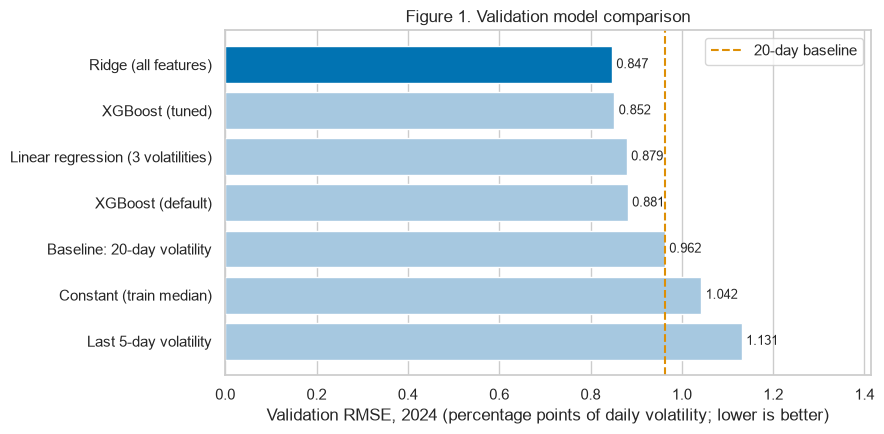

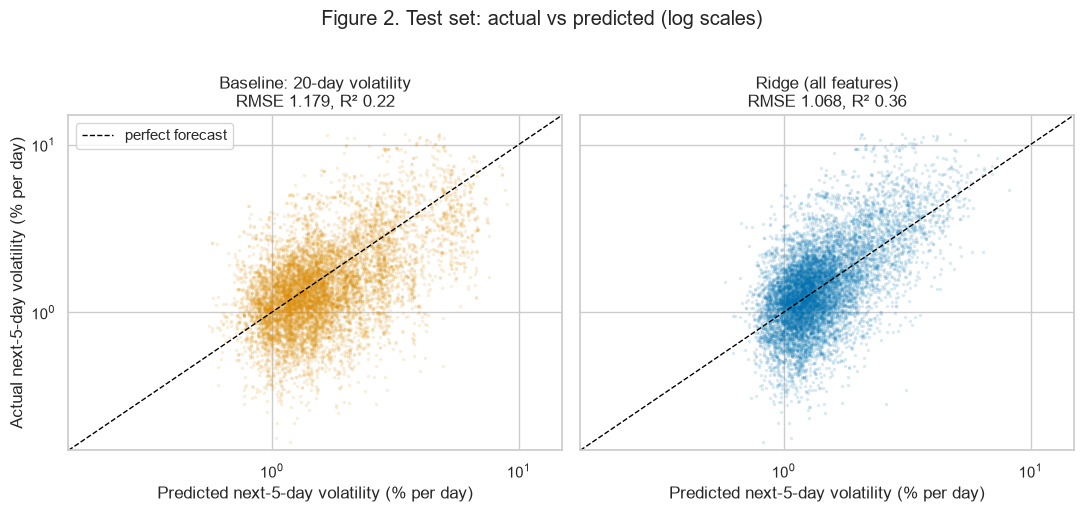

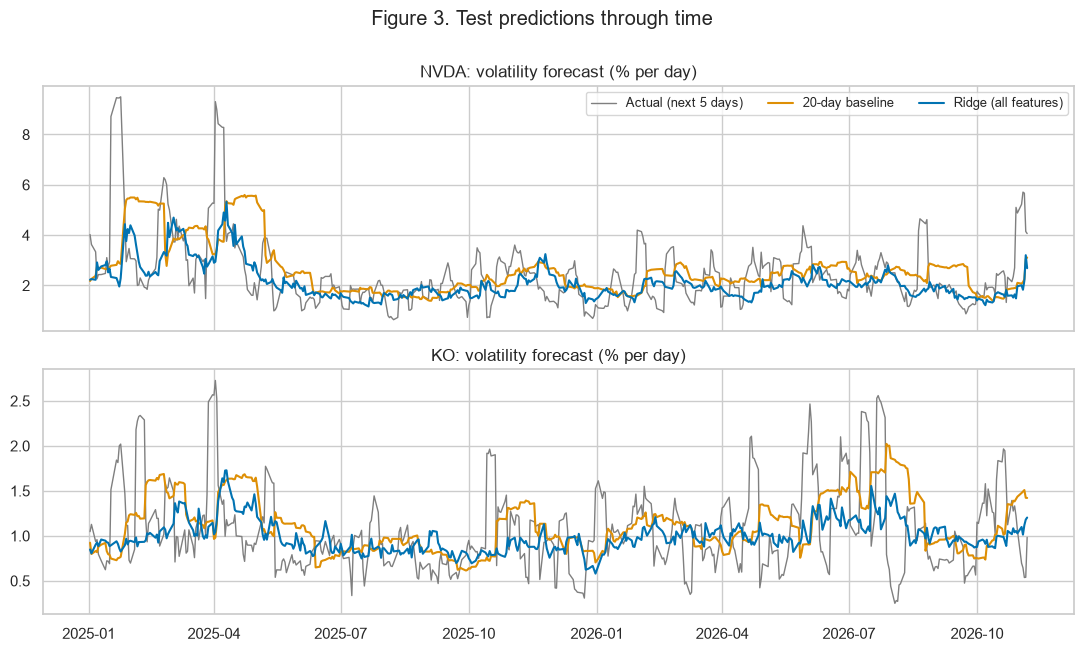

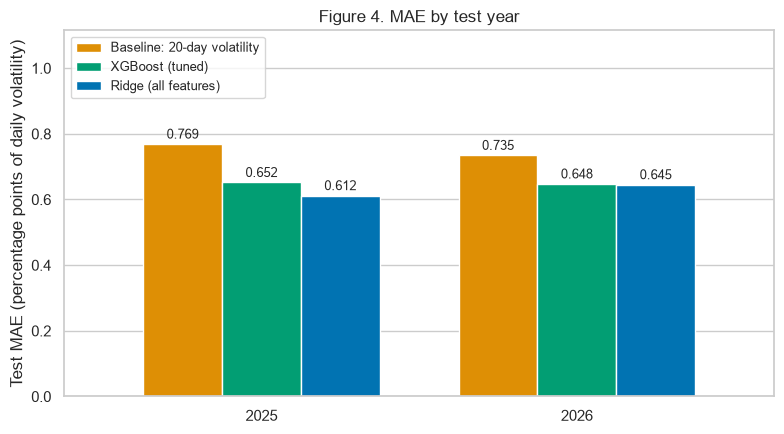

,Baseline: 20-day volatility,XGBoost (tuned),Ridge (all features)
year,,,
2025,0.7689,0.6520,0.6119
2026,0.7346,0.6476,0.6452


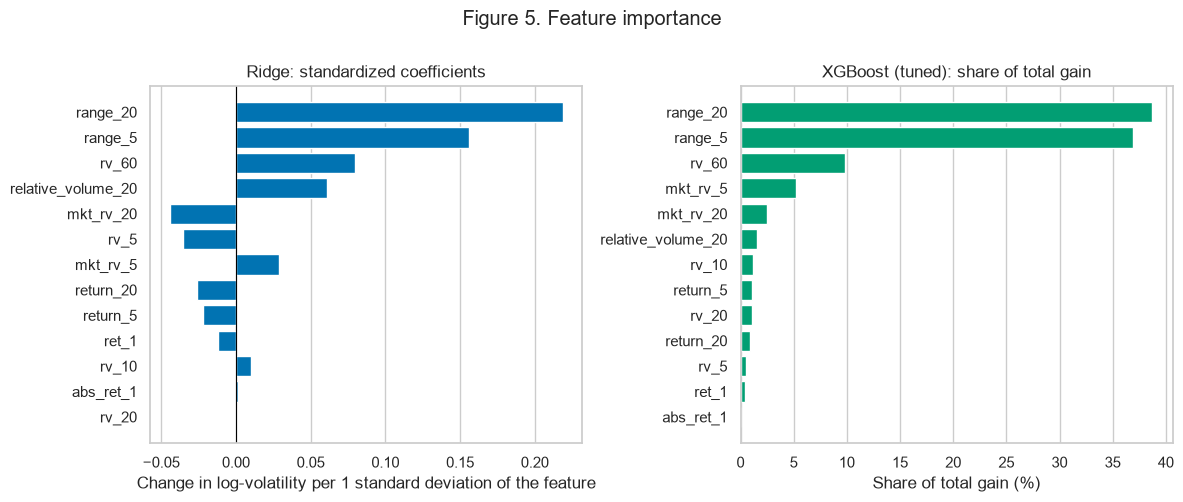

In [33]:
# Evaluation figures. FINAL is the model with the lowest validation RMSE.
FINAL = results["val_RMSE"].idxmin()
XGB = "XGBoost (tuned)"
C_BASE, C_FINAL, C_XGB, C_ACTUAL = "#de8f05", "#0173b2", "#029e73", "#7f7f7f"
print("Selected model:", FINAL)

# Figure 1: validation model comparison (which candidate worked best in 2024?)
order = results["val_RMSE"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(order.index, order.values, color=[C_FINAL if m == FINAL else "#a6c8e0" for m in order.index])
for i, v in enumerate(order.values):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
ax.axvline(results.loc[BASELINE, "val_RMSE"], color=C_BASE, linestyle="--", linewidth=1.5, label="20-day baseline")
ax.set_xlabel("Validation RMSE, 2024 (percentage points of daily volatility; lower is better)")
ax.set_title("Figure 1. Validation model comparison")
ax.set_xlim(0, order.max() * 1.25)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_validation_comparison.png")
plt.show()

# Figure 2: test actual vs predicted (accurate across low and high volatility?)
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
lims = (0.15, 15)
for ax, name, color in zip(axes, (BASELINE, FINAL), (C_BASE, C_FINAL)):
    ax.scatter(100 * test_pred[name], 100 * test["target"], s=6, alpha=0.15, color=color, linewidths=0)
    ax.plot(lims, lims, color="black", linestyle="--", linewidth=1, label="perfect forecast")
    ax.set_xscale("log"), ax.set_yscale("log"), ax.set_xlim(lims), ax.set_ylim(lims)
    ax.set_title(f"{name}\nRMSE {results.loc[name, 'test_RMSE']:.3f}, R\u00b2 {results.loc[name, 'test_R2']:.2f}")
    ax.set_xlabel("Predicted next-5-day volatility (% per day)")
axes[0].set_ylabel("Actual next-5-day volatility (% per day)")
axes[0].legend(loc="upper left")
fig.suptitle("Figure 2. Test set: actual vs predicted (log scales)", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_actual_vs_predicted.png")
plt.show()

# Figure 3: test predictions through time (does the model respond to changing conditions?)
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for ax, ticker in zip(axes, ("NVDA", "KO")):
    mask = (test["ticker"] == ticker).values
    dates = test.loc[mask, "date"]
    ax.plot(dates, 100 * test.loc[mask, "target"], color=C_ACTUAL, linewidth=1, label="Actual (next 5 days)")
    ax.plot(dates, 100 * test_pred[BASELINE][mask], color=C_BASE, linewidth=1.5, label="20-day baseline")
    ax.plot(dates, 100 * test_pred[FINAL][mask], color=C_FINAL, linewidth=1.5, label=FINAL)
    ax.set_title(f"{ticker}: volatility forecast (% per day)")
axes[0].legend(ncol=3, loc="upper right", fontsize=9)
fig.suptitle("Figure 3. Test predictions through time", y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_predictions_through_time.png")
plt.show()

# Figure 4: MAE by test year (is performance stable in 2025 vs 2026?)
abs_err = pd.DataFrame({name: 100 * np.abs(test["target"].values - test_pred[name]) for name in (BASELINE, XGB, FINAL)})
abs_err["year"] = test["date"].dt.year.values
mae_by_year = abs_err.groupby("year").mean()
ax = mae_by_year.plot(kind="bar", figsize=(8, 4.5), color=[C_BASE, C_XGB, C_FINAL], width=0.75, rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=9, padding=2)
ax.set_xlabel("")
ax.set_ylabel("Test MAE (percentage points of daily volatility)")
ax.set_title("Figure 4. MAE by test year")
ax.set_ylim(0, mae_by_year.values.max() * 1.45)
ax.grid(axis="x", visible=False)
ax.legend(title="", loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_mae_by_year.png")
plt.show()
display(mae_by_year.round(4))

# Figure 5: feature importance (which historical features appear useful?)
ridge_final = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(make_X(train_val), make_y(train_val))
ridge_coef = pd.Series(ridge_final[-1].coef_, index=FEATURES).sort_values(key=np.abs)
xgb_final = XGBRegressor(**BEST_PARAMS).fit(make_X(train_val), make_y(train_val))
gain = pd.Series(xgb_final.get_booster().get_score(importance_type="total_gain")).reindex(FEATURES).fillna(0)
gain = (100 * gain / gain.sum()).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(ridge_coef.index, ridge_coef.values, color=C_FINAL)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Ridge: standardized coefficients")
axes[0].set_xlabel("Change in log-volatility per 1 standard deviation of the feature")
axes[1].barh(gain.index, gain.values, color=C_XGB)
axes[1].set_title("XGBoost (tuned): share of total gain")
axes[1].set_xlabel("Share of total gain (%)")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle("Figure 5. Feature importance", y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig5_feature_importance.png")
plt.show()


## Model performance results


We found out that machine learning can improve short-term volatility predictions compared with baseline estimator.

Ridge Regression achieved the lowest validation RMSE of 0.847 and was selected as the final model. On the held-out test dataset, Ridge achieved an RMSE of 1.068 percentage points, compared with 1.179 for the 20-day historical-volatility baseline. It gives a 9.4% reduction in RMSE.

Ridge also achieved a lower MAE of 0.627 compared with the baseline's 0.753, representing an improvement of approximately 16.7%. Its test R² was 0.359, compared with 0.218 for the baseline.

Interestingly, increasing model complexity did not necessarily improve performance. The default XGBoost model produced a test RMSE of 1.210, which was worse than the simple historical baseline.

Hyperparameter tuning improved XGBoost's test RMSE to 1.111, but the tuned model still performed worse than Ridge Regression.

The most useful features were ```range_5``` and ```range_20``` affecting the volatility the most.

Finally, Ridge outperformed the baseline in both test years when evaluated using MAE. Meaning that the overall improvement was not restricted to a single year.

## Challenges

1. The main challenge is unpredictable market events. Historical data cannot predict unexpected news, geopolitical developments or just sudden changes in investor behavior.

2. Changes in market timeline. The validation and test periods had different volatility characteristics. Ridge's RMSE increased from 0.847 in validation to 1.068 in testing, which means that performance in one year may not fully represent general performance.

3. Dataset limitations. I only used 20 selected large-cap stocks, but they do not represent the entire stock market. Selecting them can introduce survivorship bias (focusing on winners).

4. Uncertainty. Models produced point predictions rather than prediction intervals. Volatility does not give the full associated uncertainty in the market.




## Conclusion

The main objective of this project was to determine if the machine learning can predict future stock volatility better than a simple baseline model.

The objective was achieved. Ridge Regression reduced held-out test RMSE by 9.4% compared with the 20-day historical-volatility baseline.

However, the model was less reliable when anticipating sudden volatility spikes. Its predictions were more effective at estimating general volatility conditions, disregarding extreme events discussed in challenges.

Though this project, I learned the importance of feature engineering, chronological data splitting, prevention of data leakage, comparing models against meaningful baseline, and creating separate split of validation and testing data.

## Acknowledgment and References

### Acknowledgments

- **Data.** Daily price and volume history was obtained from the Stooq historical database [1], which is free for non-commercial use.
- **AI assistance.** I used Claude (Anthropic) through Claude Code to help debug parts of the code, to verify results by re-running the pipeline independently, and to review the notebook for errors. ChatGPT (OpenAI) was used at the start to help search for ideas and scope the specific project. All results were produced by running the code in this notebook on the Stooq data, and I reviewed the analysis and conclusions.
- **Software.** The models were built with scikit-learn [4] and XGBoost [5], using pandas, NumPy, Matplotlib and seaborn for data handling and figures.

### References

1. Stooq. *Historical data: U.S. daily (ASCII)*. https://stooq.com/db/h/ (downloaded November 2026).
2. Branco, R. R., Rubesam, A., and Zevallos, M. (2024). Forecasting realized volatility: Does anything beat linear models? *Journal of Empirical Finance*, 78, 101524. https://www.sciencedirect.com/science/article/abs/pii/S0927539824000598. Motivation for comparing machine learning against simple linear models.
3. Corsi, F. (2009). A simple approximate long-memory model of realized volatility. *Journal of Financial Econometrics*, 7(2), 174-196. Source of the idea of regressing volatility on short-, medium- and long-horizon past volatility (the three-volatility linear regression).
4. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
5. Chen, T., and Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD Conference*, 785-794.